In [ ]:
import lightkurve as lk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Search MAST for TESS 2-minute cadence light curves of red dwarf TIC 307210830
search_result = lk.search_lightcurve("TIC 307210830", mission="TESS", author="SPOC", exptime=120)

# Display the table of available TESS observation sectors on MAST
print(f"Total TESS sectors found for this star: {len(search_result)}")
search_result

/home/jacob-menne/Projects/Mast/tess_exoplanet_hunter/venv/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


Total TESS sectors found for this star: 27


#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 02,2018,SPOC,120,307210830,0.0
1,TESS Sector 05,2018,SPOC,120,307210830,0.0
2,TESS Sector 08,2019,SPOC,120,307210830,0.0
3,TESS Sector 09,2019,SPOC,120,307210830,0.0
4,TESS Sector 10,2019,SPOC,120,307210830,0.0
5,TESS Sector 11,2019,SPOC,120,307210830,0.0
6,TESS Sector 12,2019,SPOC,120,307210830,0.0
7,TESS Sector 28,2020,SPOC,120,307210830,0.0
8,TESS Sector 29,2020,SPOC,120,307210830,0.0


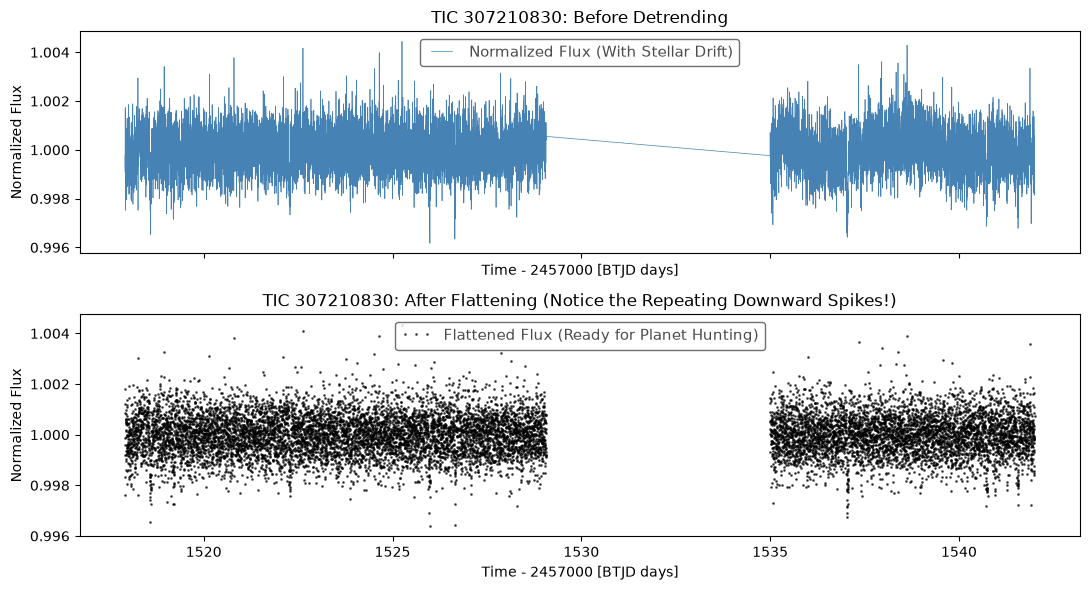

In [2]:
# Download the first available TESS sector light curve from MAST
lc_file = search_result[2].download()

# Clean out bad sensor timestamps (NaNs) and normalize brightness to centered around 1.0 (100%)
lc_clean = lc_file.remove_nans().normalize()

# Flatten the curve (remove slow wavy stellar/spacecraft drift while keeping sharp planet dips)
lc_flat = lc_clean.flatten(window_length=401)

# Plot the before-and-after comparison
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

lc_clean.plot(ax=ax1, color="steelblue", label="Normalized Flux (With Stellar Drift)")
ax1.set_title("TIC 307210830: Before Detrending")

lc_flat.plot(ax=ax2, color="black", marker=".", linestyle="none", markersize=2, alpha=0.6, label="Flattened Flux (Ready for Planet Hunting)")
ax2.set_title("TIC 307210830: After Flattening (Notice the Repeating Downward Spikes!)")

plt.tight_layout()
plt.show()

Detected Orbital Period: 3.6911 days
Transit Depth (fraction of starlight blocked): 0.001390 (0.139%)


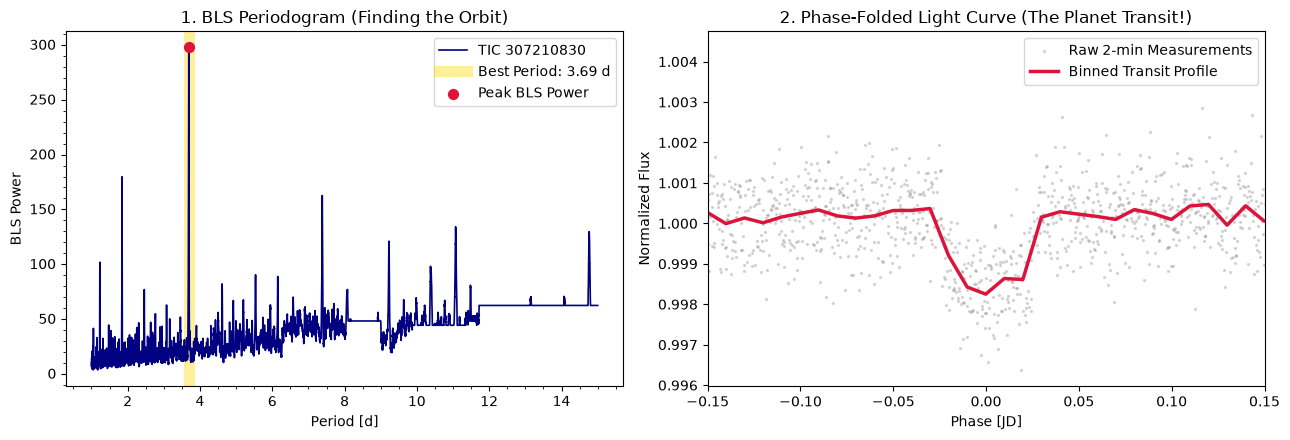

In [3]:
# Run the Box Least Squares (BLS) periodogram searching periods from 1 to 15 days
period_grid = np.linspace(1, 15, 10000)
bls = lc_flat.to_periodogram(method="bls", period=period_grid, frequency_factor=500)

# Extract the strongest planet signal (Period, First Transit Time, and Transit Depth)
best_period = bls.period_at_max_power.value
best_t0 = bls.transit_time_at_max_power.value
transit_depth = bls.depth_at_max_power.value

print(f"Detected Orbital Period: {best_period:.4f} days")
print(f"Transit Depth (fraction of starlight blocked): {transit_depth:.6f} ({transit_depth*100:.3f}%)")

# Plot the BLS Periodogram (left) and the Phase-Folded Transit Dip (right)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Left plot: Draw the BLS curve in front (zorder=3)
bls.plot(ax=ax1, color="navy", lw=1.2, zorder=3)

# Highlight the best period BEHIND the blue spike (zorder=0) + mark the tip with a red dot
ax1.axvline(best_period, color="gold", lw=8, alpha=0.4, zorder=0, label=f"Best Period: {best_period:.2f} d")
ax1.scatter([best_period], [bls.max_power.value], color="crimson", s=50, zorder=5, label="Peak BLS Power")
ax1.set_title("1. BLS Periodogram (Finding the Orbit)")
ax1.legend()

# Right plot: Fold all orbits on top of each other to reveal the transit shape
folded_lc = lc_flat.fold(period=best_period, epoch_time=best_t0)
folded_lc.scatter(ax=ax2, color="gray", alpha=0.25, s=8, label="Raw 2-min Measurements")

# Overlay a binned moving average in red to make the U-shaped planet dip pop out
folded_lc.bin(time_bin_size=0.01).plot(ax=ax2, color="crimson", lw=2.5, label="Binned Transit Profile")
ax2.set_xlim(-0.15, 0.15)
ax2.set_title("2. Phase-Folded Light Curve (The Planet Transit!)")
ax2.legend()

plt.tight_layout()
plt.show()

In [4]:
from astroquery.mast import Catalogs

# Fetch the host star's physical properties from the MAST TESS Input Catalog
star_row = Catalogs.query_object("TIC 307210830", radius=0.01, catalog="TIC").to_pandas().iloc[0]
R_star = star_row["rad"]      # Star radius in Solar radii
M_star = star_row["mass"]     # Star mass in Solar masses
T_star = star_row["Teff"]     # Star temperature in Kelvin
J_mag  = star_row["Jmag"]     # Infrared J-band brightness (used for JWST scoring)

# Calculate Planet Radius in Earth Radii (1 Solar Radius = 109.076 Earth Radii)
R_planet_earth = R_star * np.sqrt(transit_depth) * 109.076

# Calculate Orbital Distance (Semi-major axis 'a' in AU via Kepler's Third Law)
a_au = (M_star * (best_period / 365.25) ** 2) ** (1 / 3)

# Calculate Planet Equilibrium Temperature (Kelvin, assuming 0.3 Earth-like reflectivity/albedo)
# Note: 1 AU = 215.032 Solar Radii
a_solar_radii = a_au * 215.032
T_eq = T_star * np.sqrt(R_star / (2 * a_solar_radii)) * ((1 - 0.3) ** 0.25)

# Estimate Planet Mass (Chen & Kipping empirical relation) & JWST Atmospheric Score (TSM)
M_planet_earth = R_planet_earth ** 2.06 if R_planet_earth < 1.23 else 1.436 * (R_planet_earth ** 1.7)
scale_factor = 0.190 if R_planet_earth < 1.5 else 1.26
tsm_score = scale_factor * ((R_planet_earth ** 3) * T_eq / (M_planet_earth * (R_star ** 2))) * (10 ** (-J_mag / 5))

# Display a clean scorecard and a side-by-side comparison scorecard against the Sun and Earth
scorecard = pd.DataFrame({
    "Metric": [
        "Host Star Teff (K)",
        "Host Star Radius (Solar)",
        "Orbital Period (1 Year)",
        "Orbital Distance (AU)",
        "Transit Depth (% Light Blocked)",
        "Planet Radius (Earth = 1.0)",
        "Equilibrium Temp (K / °C)",
        "JWST Atmospheric Score (TSM)"
    ],
    "Detected Planet (TIC 307210830 c)": [
        f"{T_star:.0f} K",
        f"{R_star:.2f} R_sun",
        f"{best_period:.4f} days",
        f"{a_au:.4f} AU",
        f"{transit_depth * 100:.3f}%",
        f"{R_planet_earth:.2f} R_earth",
        f"{T_eq:.0f} K ({T_eq - 273.15:.0f} °C)",
        f"{tsm_score:.1f} (High Priority > 10)"
    ],
    "Earth & Sun (Reference)": [
        "5772 K",
        "1.00 R_sun",
        "365.2500 days",
        "1.0000 AU",
        "0.008% (from afar)",
        "1.00 R_earth",
        "255 K (-18 °C bare / +15 °C surface)",
        "Baseline Reference"
    ]
})

display(scorecard)

,Metric,Detected Planet (TIC 307210830 c),Earth & Sun (Reference)
0,Host Star Teff (K),3429 K,5772 K
1,Host Star Radius (Solar),0.31 R_sun,1.00 R_sun
2,Orbital Period (1 Year),3.6911 days,365.2500 days
3,Orbital Distance (AU),0.0310 AU,1.0000 AU
4,Transit Depth (% Light Blocked),0.139%,0.008% (from afar)
5,Planet Radius (Earth = 1.0),1.28 R_earth,1.00 R_earth
6,Equilibrium Temp (K / °C),481 K (208 °C),255 K (-18 °C bare / +15 °C surface)
7,JWST Atmospheric Score (TSM),23.0 (High Priority > 10),Baseline Reference


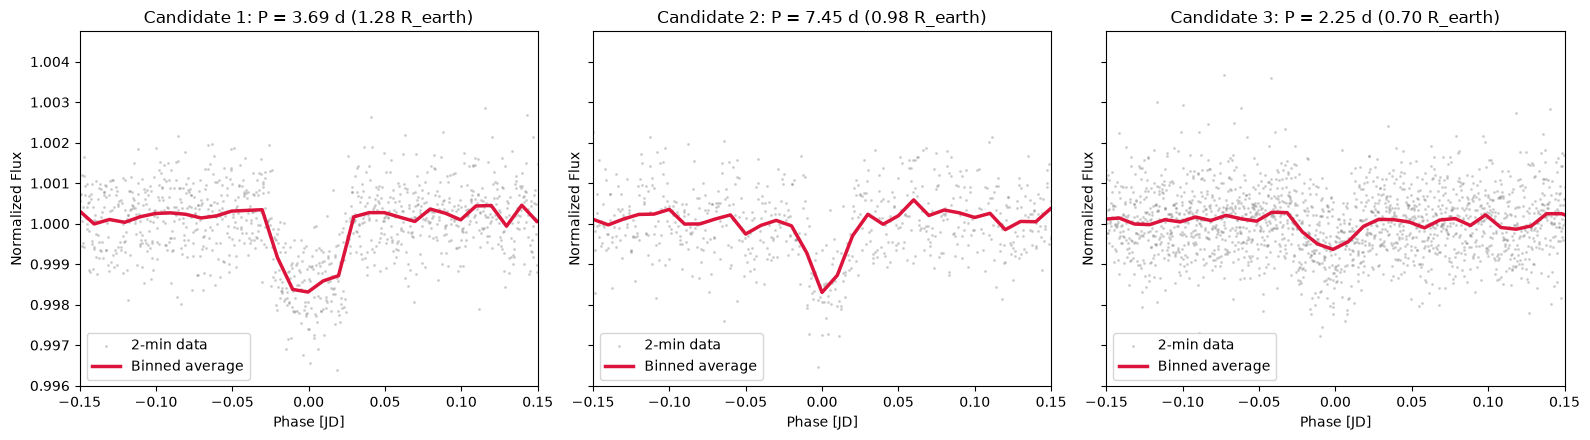

,Pass #,Orbital Period (d),Transit Depth (%),Planet Radius (R_earth),Orbit Distance (AU),Equilibrium Temp (°C),BLS Power,JWST TSM Score
0,Candidate 1,3.6913,0.140,1.28,0.0310,208 °C (481 K),301.0,23.1
1,Candidate 2,7.4500,0.082,0.98,0.0496,108 °C (381 K),63.2,18.6
2,Candidate 3,2.2534,0.042,0.70,0.0223,294 °C (567 K),49.5,20.3


In [5]:
# Start with a fresh copy of our flattened light curve from Cell 2
lc_search = lc_flat.copy()

detected_planets = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

# Search for up to 3 planets iteratively
for i in range(3):
    # Run BLS on the remaining unmasked starlight (searching 1.5 to 15 days)
    period_grid = np.linspace(1.5, 15, 10000)
    bls = lc_search.to_periodogram(method="bls", period=period_grid, frequency_factor=500)
    
    # Extract the strongest peak in this pass
    period = bls.period_at_max_power.value
    t0 = bls.transit_time_at_max_power.value
    duration = bls.duration_at_max_power.value
    depth = bls.depth_at_max_power.value
    power = bls.max_power.value
    
    # Calculate physical properties & JWST Atmospheric Score (TSM)
    r_earth = R_star * np.sqrt(depth) * 109.076
    a_au = (M_star * (period / 365.25) ** 2) ** (1 / 3)
    t_eq = T_star * np.sqrt(R_star / (2 * a_au * 215.032)) * ((1 - 0.3) ** 0.25)
    
    m_earth = r_earth ** 2.06 if r_earth < 1.23 else 1.436 * (r_earth ** 1.7)
    scale_fac = 0.190 if r_earth < 1.5 else 1.26
    tsm = scale_fac * ((r_earth ** 3) * t_eq / (m_earth * (R_star ** 2))) * (10 ** (-J_mag / 5))
    
    detected_planets.append({
        "Pass #": f"Candidate {i+1}",
        "Orbital Period (d)": round(period, 4),
        "Transit Depth (%)": round(depth * 100, 3),
        "Planet Radius (R_earth)": round(r_earth, 2),
        "Orbit Distance (AU)": round(a_au, 4),
        "Equilibrium Temp (°C)": f"{t_eq - 273.15:.0f} °C ({t_eq:.0f} K)",
        "BLS Power": round(power, 1),
        "JWST TSM Score": round(tsm, 1)
    })
    
    # Plot this candidate's phase-folded transit dip
    ax = axes[i]
    folded = lc_search.fold(period=period, epoch_time=t0)
    folded.scatter(ax=ax, color="gray", alpha=0.25, s=6, label="2-min data")
    folded.bin(time_bin_size=0.01).plot(ax=ax, color="crimson", lw=2.5, label="Binned average")
    ax.set_xlim(-0.15, 0.15)
    ax.set_title(f"Candidate {i+1}: P = {period:.2f} d ({r_earth:.2f} R_earth)")
    ax.legend(loc="lower left")
    
    # Mask out this planet's transits (2x duration buffer to catch ingress/egress edges)
    transit_mask = bls.get_transit_mask(period=period, transit_time=t0, duration=duration * 2.0)
    lc_search = lc_search[~transit_mask]

plt.tight_layout()
plt.show()

# Display the multi-planet summary table
multi_planet_df = pd.DataFrame(detected_planets)
display(multi_planet_df)